# Euclidean distance, global shifts and DTW — 2026-10-15

A revised analysis and figure notebook using the completed **2026-09-24 focused extraction (pyspi computation r7)**: 50 independent MTS instances per condition, 350 recordings. The notebook date is the analysis date; no new extraction is implied.

The question is whether agreement between three distances distinguishes fixed timing offsets from local time deformation. The construction changes allowable alignment requirements while the distance cost and normalisation stay matched. We first inspect observed channels and their generating clocks, then fitted alignments for the same edge, and finally the profiles across all channel pairs and independent recordings.

In [1]:
from pathlib import Path
import sys, json
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from research.cases.refresh_case_figures import (
    analyze, plot_pair_rainclouds, plot_rmi_channel_pairs,
    plot_mi_sensitivity, plot_spi_planes, plot_dtw_pair_sweep,
)
DATA = ROOT / 'data/cases/dtw-euclidean-260924/data'
OUT = ROOT / 'results/cases/dtw-euclidean-261015'
# Reanalyse the archived focused SPIs; do not recompute or mix computation versions.
frame = analyze(DATA, 'dtw', OUT)
audit = json.loads((OUT / 'audit.json').read_text())
print(f"{audit['datasets']} datasets; {len(audit['spis'])} focused SPIs; {audit['nonfinite_off_diagonal_values']} nonfinite off-diagonal values")
from research.cases.case_mechanisms import (plot_dtw_construction, plot_dtw_pair_inspections, analyze_realized_warp, plot_realized_warp)

350 datasets; 3 focused SPIs; 0 nonfinite off-diagonal values


Construction: noisy copies of an AR(1) mother ($a=0.5$) receive fixed integer lags spanning 0–5 and independent local rebound warps. At each path decision, probability $p_{\rm step}$ initiates a size-3 excursion; otherwise the path advances diagonally. This parameter is a path-generation probability, not the fraction of samples warped. Channels are then standardised. Noise standard deviations are uniform on $[0.1/2.718,\,0.1\times2.718]$. Existing recordings have $M=20$, $T=1000$; future cases can be smaller.

The seven conditions are no lag/no warp; lag only; then lag plus $p_{\rm step}\in\{0.1,0.3,0.5,0.7,0.9\}$. The distinction is the allowed alignment: Euclidean compares contemporaneous samples, shifted distance permits one global displacement, and DTW permits local time deformation.

More explicitly, $x_i(t)=\mathrm{standardise}\{s[\tau_{\max}-\tau_i+h_i(t)]+\eta_i(t)\}$, where $h_i(t)=t$ without local warping. The lower panels plot $t_{\rm orig}=h_i(t_{\rm warp})-\tau_i$: mother indices use an origin shifted by $\tau_{\max}$. The dashed line is identity. A constant lag gives a parallel offset; a local warp adds plateaus and jumps. These are generating maps, not fitted DTW paths, and can map several observations to the same mother sample.

Use predetermined instance 0 in each condition and channels 1 and 20 throughout. The recordings in different conditions are separate realisations. All heatmaps show samples 100–159 with a common ±3 SD colour scale; the map panels show the same window. Stored-seed replay is checked against the archived observations before displaying the maps.

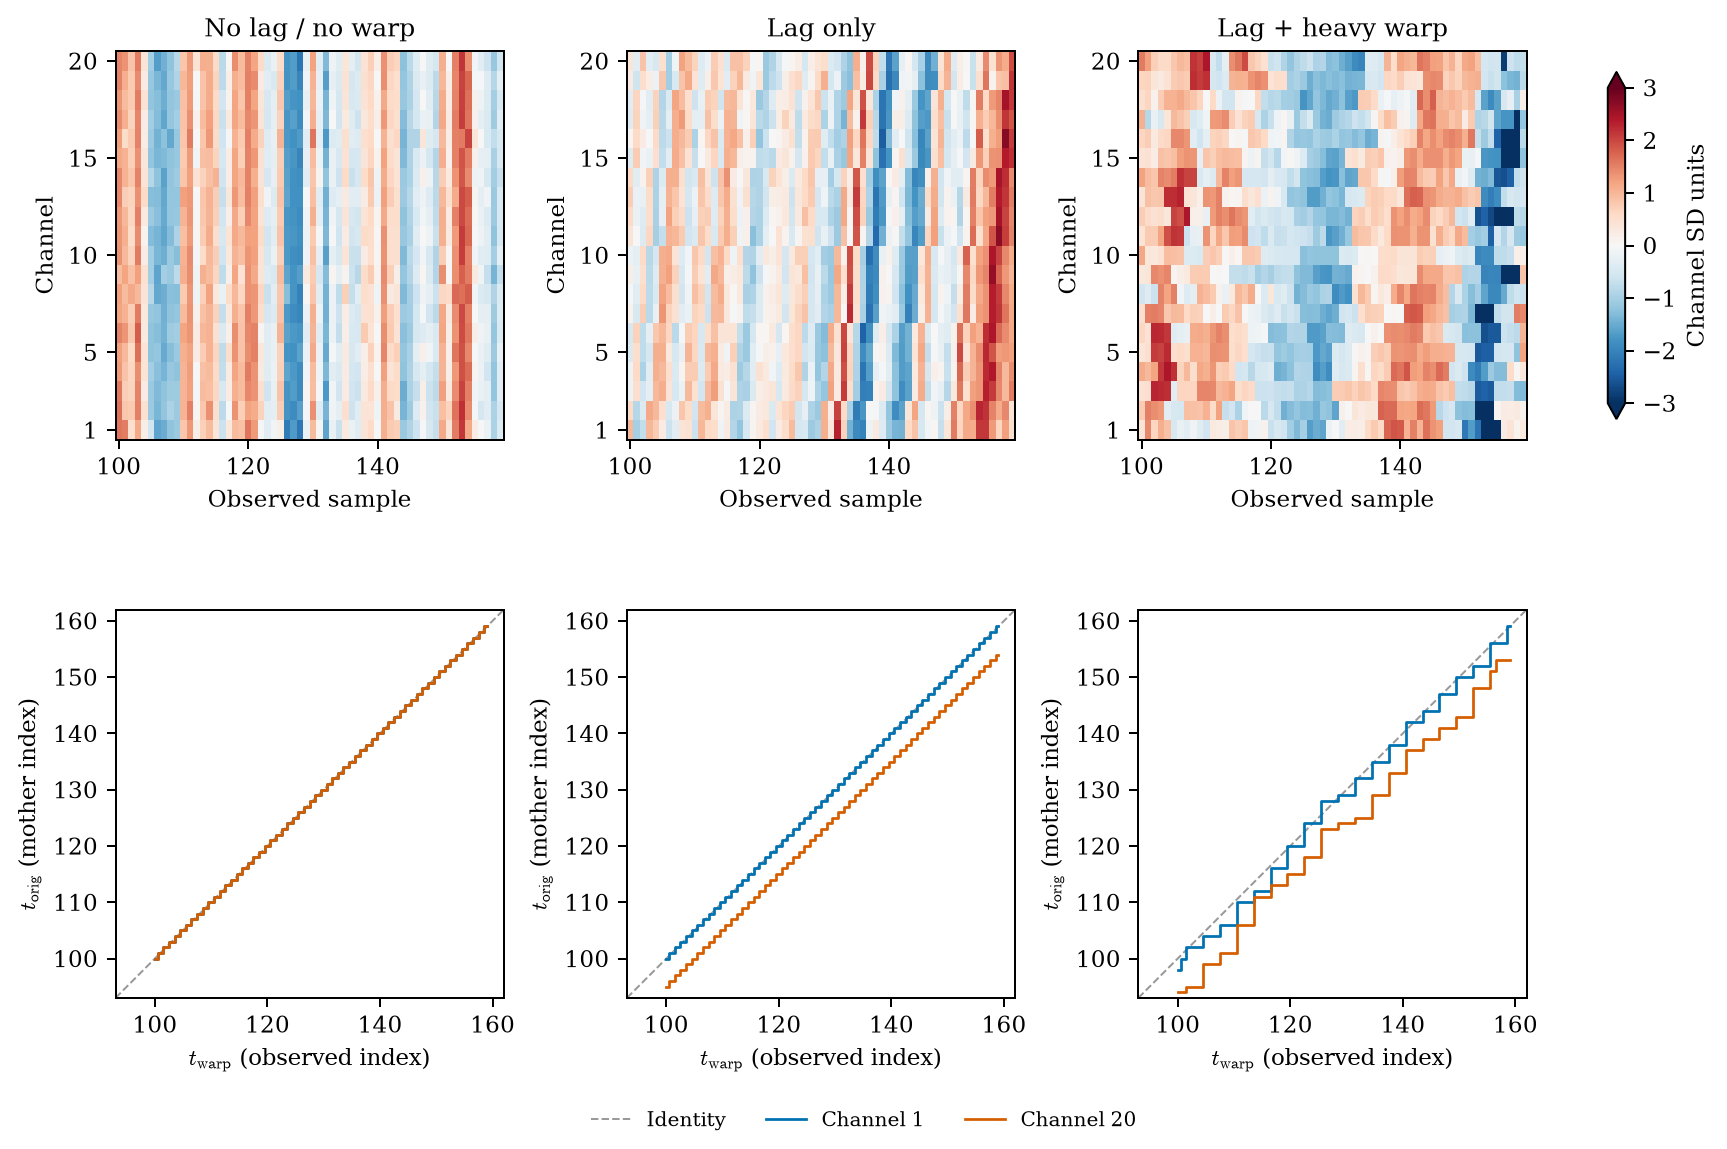

In [2]:
fig = plot_dtw_construction(frame, OUT)
plt.show()

All three distances use squared-error costs followed by a square root and division by $\sqrt T$. Shifted distance minimises over shifts -10 through 10, including boundary costs; unrestricted DTW permits a larger set of paths. Thus $\mathrm{DTW}\leq\mathrm{shifted}\leq\mathrm{Euclidean}$ is structural, not evidence of correct physical alignment. The divisor is record length, not path length. There are no hierarchy violations among the 66,500 unique pairs in these recordings.

Inspect edge A (channels 1–20) before pooling edges. The upper panels show the observed signals; the lower panels compare the best global-shift path with the fitted DTW path and identity. Fits and distance values use all 1,000 samples; only samples 100–160 are displayed. All three recomputed edge costs are checked against the archived SPI entries. Colours of channel traces match the generating-map figure. The shift sign convention matches channel-1 sample k+s to channel-20 sample k. A lower DTW cost is expected from the larger path set and does not establish correct recovery of the generating map.

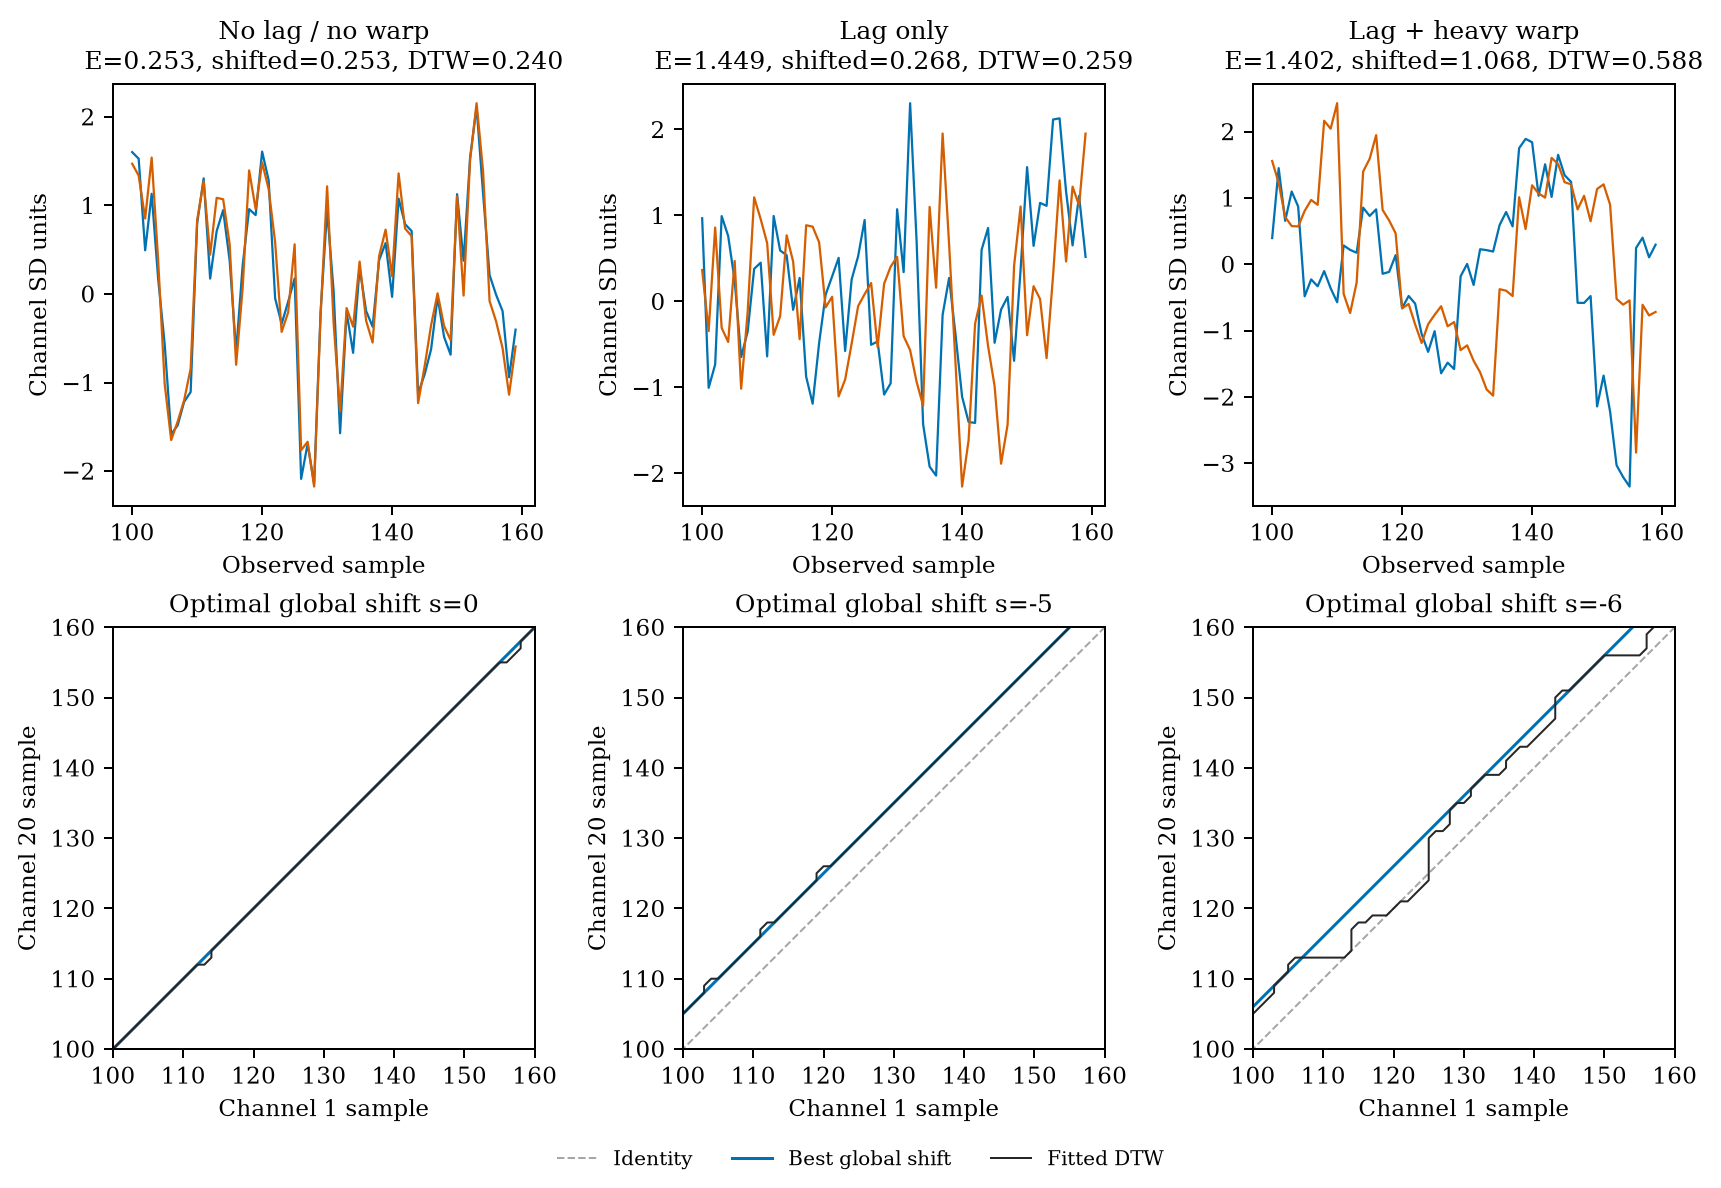

In [3]:
fig = plot_dtw_pair_inspections(frame, OUT)
plt.show()

Now place the same edge A inside the full SPI–SPI profile of each recording. Colour encodes the absolute generating lag difference for every unordered pair; the circled point is channels 1–20. The remaining cloud shows why one selected edge cannot determine z. Dashed lines mark equal distances; matching x/y scales within each panel make the distance hierarchy visible. Limits vary between panels.

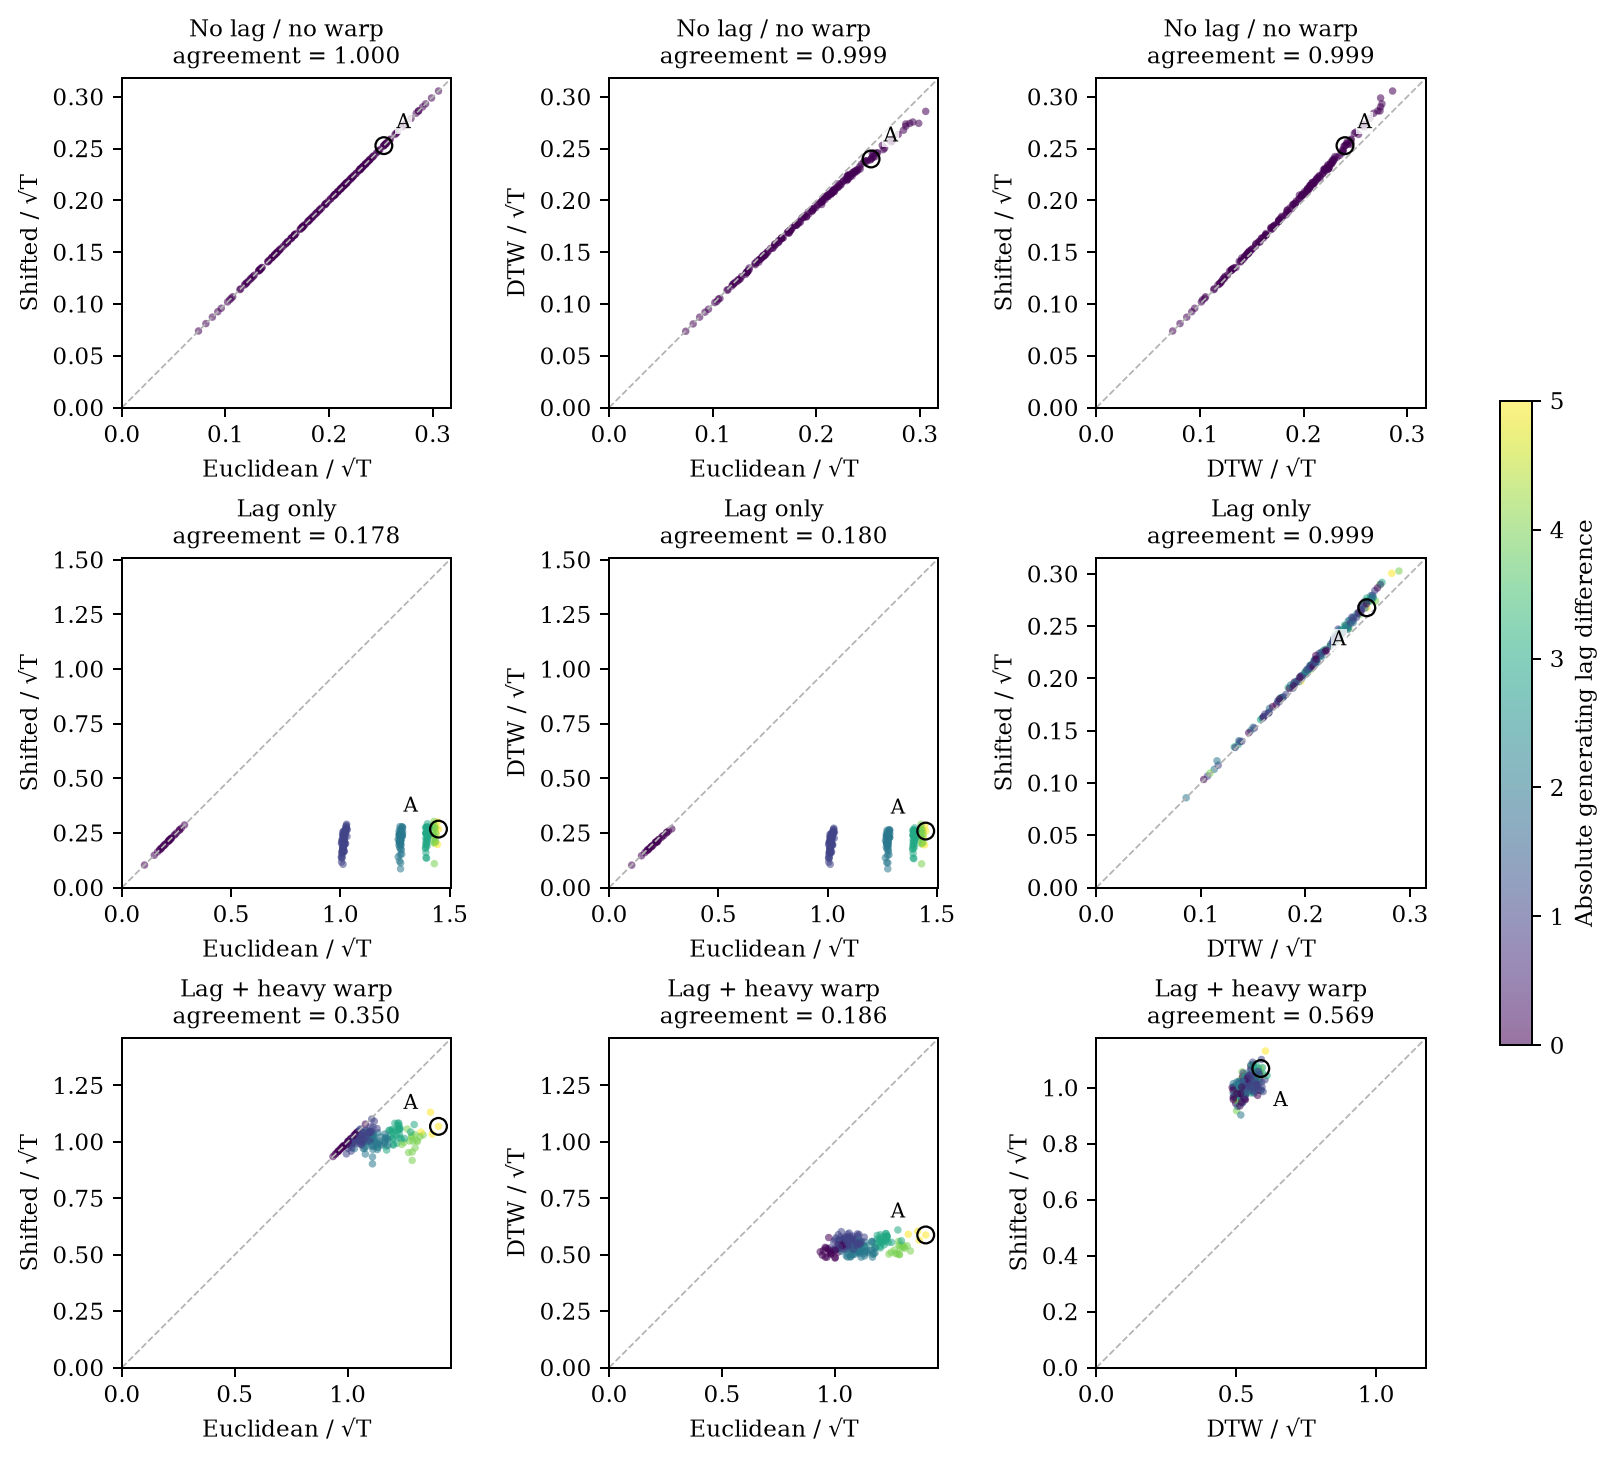

In [4]:
fig = plot_spi_planes(frame, 'dtw', OUT, highlight_edges=True)
plt.show()

For each recording, $z_{ab}=\mathrm{corr}_{i<j}(A^{(a)}_{ij},A^{(b)}_{ij})$. This measures linear agreement between SPI profiles over unique unordered channel pairs. Channel pairs within one recording are dependent; the independent replication unit is the MTS instance. Constant profiles have undefined $z$. The sweep shows mean $z$, with pointwise 95% Student-t intervals over 50 independent recordings. Each SPI pair has its own y-scale, held fixed across conditions. The no-lag control is separated from the connected lagged sweep because it changes a second parameter.

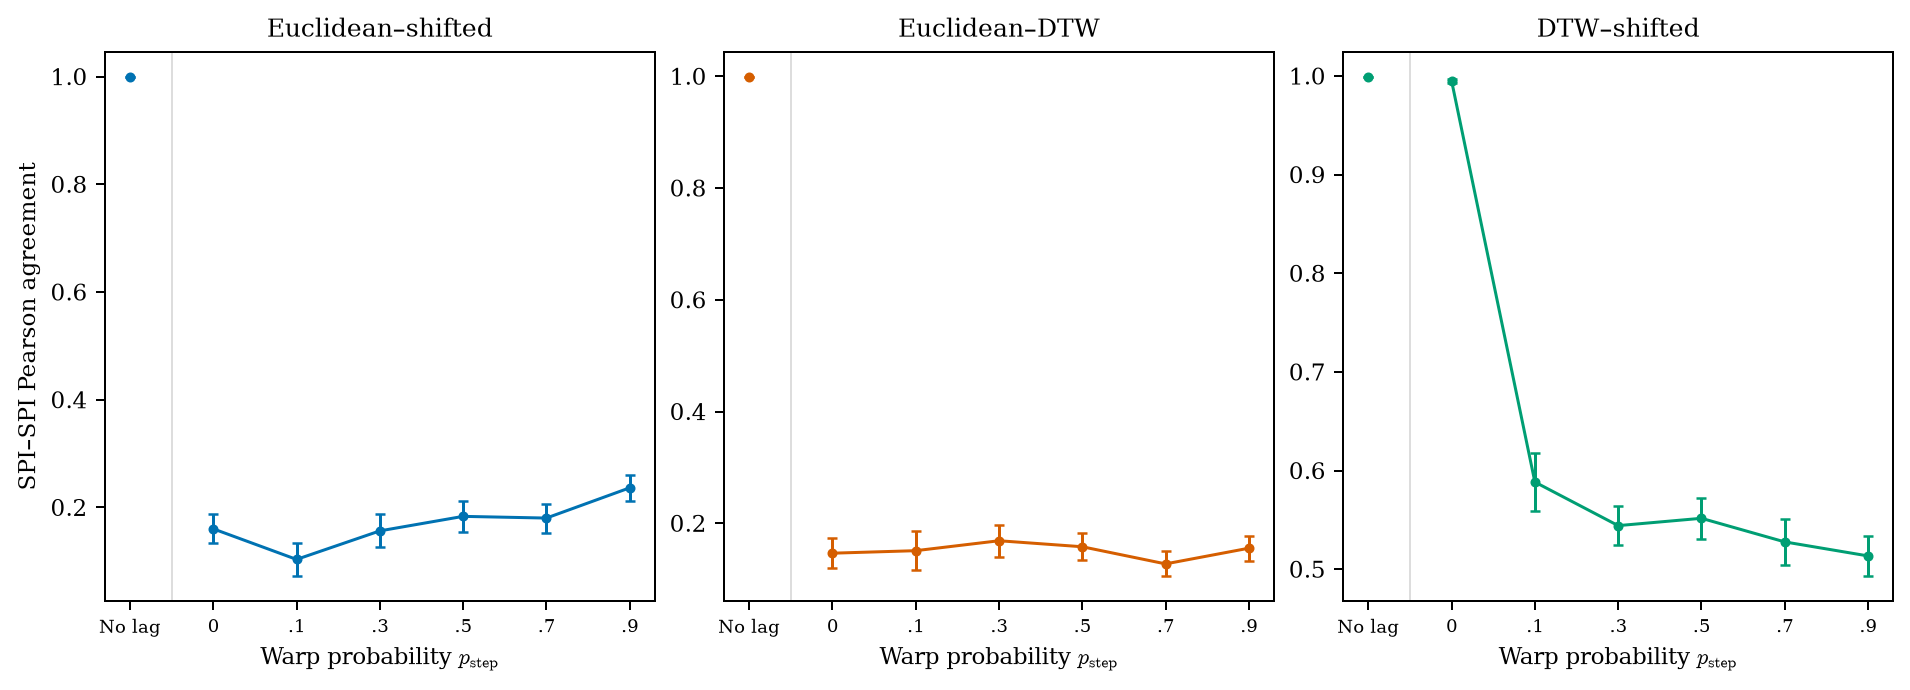

In [5]:
fig = plot_dtw_pair_sweep(frame, OUT)
plt.show()

Lag alone separates Euclidean from both alignment-aware distances, while mean DTW–shifted agreement stays about 0.995. With local warping, the latter falls to roughly 0.51–0.59; the decline is not strictly monotonic with path-step probability. This supports a distinction between global and local alignment tolerance, not a calibrated measure of warp amount.

The inspected lag-only edge has best shift −5, while the heavily warped edge has best shift −6 despite generating lag difference 5. This illustrates why generating lag and optimal fitted shift are distinct. The generating map is many-to-one and the signals are noisy; direct alignment-recovery claims would need a separately defined ground-truth criterion.

Check what the warp setting actually changes. Recover $h_i(t)$ for every recording and verify its generated observation against the archive. Define $\delta_i(t)=h_i(t)-t$ and measure $D=M^{-1}\sum_i\mathrm{SD}_t[\delta_i(t)]$. This removes each channel's mean warp offset and measures the time-varying deformation in samples. Fixed generating lag is excluded as well. The left panel shows means and pointwise 95% Student-t intervals across 50 independent recordings per setting; the right shows one point per recording. Both use the lag-0–5 conditions, separating them from the no-lag control.

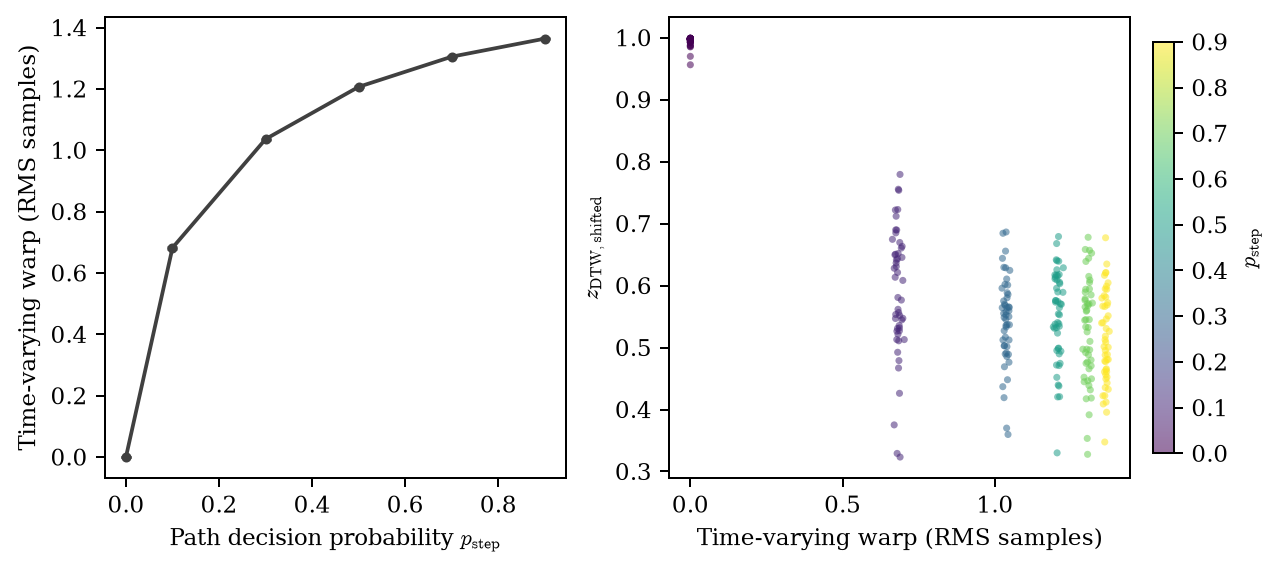

In [6]:
warp = analyze_realized_warp(frame, OUT)
fig = plot_realized_warp(warp, OUT)
plt.show()

Time-varying deformation increases with the warp setting, while DTW–shifted agreement drops sharply on introducing warping and then mostly plateaus. This supports a global-versus-local alignment contrast, not a linear warp-amount axis.

The actual path-to-index conversion averages visited mother indices, rounds, and fills unvisited output indices through cumulative monotonicity. Consequently the resulting map need not have zero-mean displacement even though excursion vertices return to the identity. At p_step=0.9, the mean signed offset is −0.908 samples and the centred RMS deformation is 1.364 samples (averages over 50 recordings). The CSV retains signed offsets, absolute offsets and displaced fractions alongside the centred diagnostic; $p_{\rm step}$ is not the fraction of samples warped. A future strictly centred-warp experiment would need a different construction and fresh data. No generator or archived observation is changed here.

Configurations: `research/cases/ed_xed_dtw/configs/260924_lagged-warping.yaml` and `260924_lagged-warping-extra.yaml`; SPI definitions: `research/cases/ed_xed_dtw/spis/dtw_euclidean_norm.yaml`. Figures and audits are saved under `results/cases/dtw-euclidean-261015/`.